# Machine Learning-Based Imputation Techniques: Analysis and Study

Code for my IEEE paper, **[Machine Learning-Based Imputation Techniques Analysis and Study](https://ieeexplore.ieee.org/document/10739330)** (Agnal Varghese Pindiyan and Pramila R.M., CHRIST University).

**Research question:** When a medical dataset has missing values, does the choice of imputation method change how well a classifier predicts diabetes?

This notebook has two parts:
- **Part A: the paper's experiment.** My original four notebooks (median/mean, KNN, Random Forest and SVM imputation) combined into one, reproducing the method in the paper.
- **Part B: revisiting the results (2026).** Two questions I would now add as a reviewer: are the differences between methods bigger than random noise, and how accurately does each method recover the true missing values?

## Summary

1. **About 11% of all values are missing**, concentrated in Insulin (49%) and SkinThickness (30%). They are recorded as 0 in the raw data, which is impossible for these measurements.
2. **In the paper, Random Forest was the strongest classifier under every imputation method**, and for Random Forest the imputation method changed mean F1 by less than 1 percentage point (65.8–66.5%).
3. **Part B shows those differences are within noise.** Across 25 cross-validation fits, F1 for a single method varies by about ±4.7 points, while the gap between the best and worst imputation method is about 1 point. On this dataset, simple median imputation is as good a choice as the machine-learning imputers for classification.
4. **The imputers differ more clearly in how accurately they recover the missing values themselves.** Random Forest imputation has about 15% lower error than the median. This matters if the imputed values are used directly, for example in a report of patients' insulin levels.

## 1. Setup

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.svm import SVC, SVR
from sklearn.metrics import roc_auc_score, roc_curve, f1_score
from sklearn.base import clone

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
import os
os.makedirs("images", exist_ok=True)
RANDOM_STATE = 42
TEAL, AMBER, GREY = "#1F5F6B", "#B87A12", "#C9D4DC"

## 2. Data

The [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database): 768 women of Pima heritage, 8 health measurements, and whether they were diagnosed with diabetes (`Outcome`).

In the raw data, missing measurements are stored as **0**. A glucose level, blood pressure, skin thickness, insulin level, BMI or age of 0 is impossible, so I convert these zeros to missing values.

In [2]:
df = pd.read_csv("diabetes1.csv")
features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
zero_means_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "Age"]
df[zero_means_missing] = df[zero_means_missing].replace(0, np.nan)

print(df.shape)
print(f"Outcome: {df['Outcome'].mean():.1%} diabetic (class imbalance)")
df.head()

(768, 9)
Outcome: 34.9% diabetic (class imbalance)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50.0,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31.0,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32.0,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,NaN,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1


Missing cells overall: 10.7%


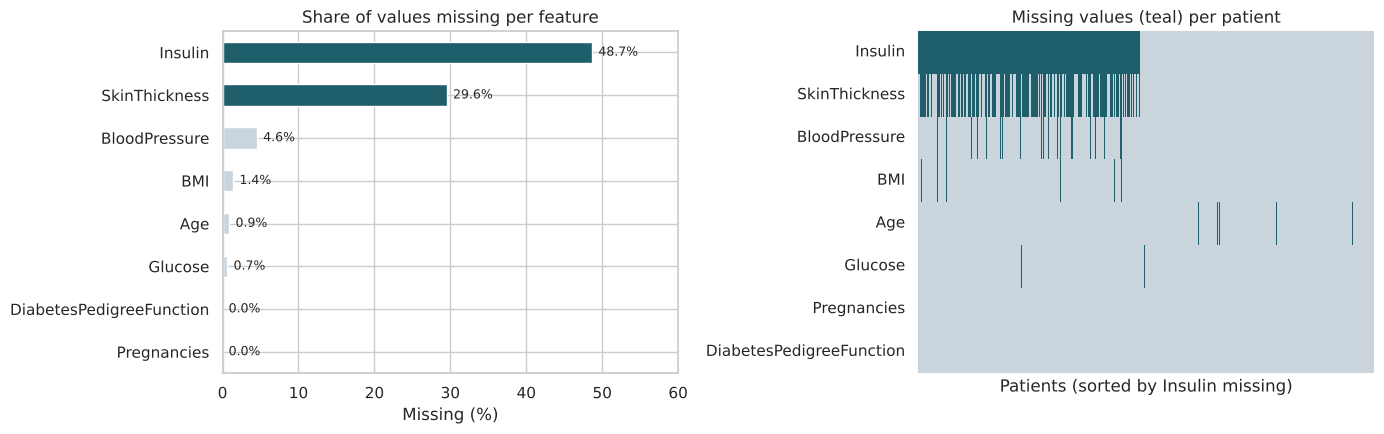

In [3]:
missing = df[features].isnull().mean().mul(100).sort_values()
print(f"Missing cells overall: {df[features].isnull().values.mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
missing.plot.barh(ax=axes[0], color=[TEAL if v > 10 else GREY for v in missing])
for i, v in enumerate(missing):
    axes[0].text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlim(0, 60)
axes[0].set_xlabel("Missing (%)")
axes[0].set_title("Share of values missing per feature")

order = df[features].isnull().sum().sort_values(ascending=False).index
sns.heatmap(df.sort_values("Insulin", na_position="first")[order].isnull().T, cbar=False, ax=axes[1],
            cmap=[GREY, TEAL], xticklabels=False)
axes[1].set_xlabel("Patients (sorted by Insulin missing)")
axes[1].set_title("Missing values (teal) per patient")
plt.tight_layout()
plt.savefig("images/missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

Insulin and SkinThickness are missing together for many patients (they were usually measured in the same test), which is why multivariate imputers that use the other features can help.

## Part A: the paper's experiment

**Method, as in the paper**
1. Split the data 80/20 into training and test sets.
2. Impute missing values with each of four methods, fitting the imputer on the training set:
   - **Median/mean:** mean for Glucose, BloodPressure and BMI; median for the more skewed SkinThickness, Insulin and Age.
   - **KNN:** `KNNImputer` with 5 neighbours.
   - **Random Forest:** `IterativeImputer` with a `RandomForestRegressor`.
   - **SVM:** `IterativeImputer` with an `SVR`.
3. For each imputed dataset, tune three classifiers with `GridSearchCV` and 5-fold `StratifiedKFold`: KNN (with scaling), Random Forest, and SVM (polynomial kernel).
4. Report the mean accuracy, precision, recall and F1 from 5-fold cross-validation on the training set, plus accuracy and ROC-AUC on the test set.

*Note:* in my original median notebook, the median was calculated on the full dataset before splitting. Here every imputer is fitted on the training set only, as the KNN, Random Forest and SVM notebooks already did. The Random Forest grid and the Random Forest imputer are also smaller than in the original notebooks, to keep the run time to a few minutes, so numbers may differ slightly from the paper.

In [4]:
X = df[features]
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

mean_cols = ["Glucose", "BloodPressure", "BMI"]
median_cols = ["SkinThickness", "Insulin", "Age"]
other_cols = [c for c in features if c not in mean_cols + median_cols]

def make_imputers():
    return {
        "Median/Mean": ColumnTransformer([
            ("mean", SimpleImputer(strategy="mean"), mean_cols),
            ("median", SimpleImputer(strategy="median"), median_cols),
            ("rest", "passthrough", other_cols),
        ]),
        "KNN": KNNImputer(n_neighbors=5),
        "Random Forest": IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE),
                                          random_state=RANDOM_STATE, max_iter=5),
        "SVM": IterativeImputer(estimator=SVR(), random_state=RANDOM_STATE, max_iter=10),
    }

classifier_grids = {
    "KNN": (Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
            {"knn__n_neighbors": [3, 5, 7], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [100, 300], "max_depth": [None, 10], "min_samples_split": [2, 10], "min_samples_leaf": [1, 4]}),
    "SVM": (SVC(kernel="poly"), {"C": [0.1, 1, 10, 100]}),
}

Train: 614 | Test: 154


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, roc_data = [], {}
start = time.time()

for imp_name, imputer in make_imputers().items():
    Xtr = imputer.fit_transform(X_train)
    Xte = imputer.transform(X_test)
    for clf_name, (estimator, grid) in classifier_grids.items():
        search = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(Xtr, y_train)
        best = search.best_estimator_
        s = cross_validate(best, Xtr, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
        scores = best.predict_proba(Xte)[:, 1] if hasattr(best, "predict_proba") else best.decision_function(Xte)
        rows.append({"imputation": imp_name, "classifier": clf_name,
                     "mean accuracy": s["test_accuracy"].mean(), "mean precision": s["test_precision"].mean(),
                     "mean recall": s["test_recall"].mean(), "mean F1": s["test_f1"].mean(),
                     "test accuracy": best.score(Xte, y_test), "test ROC-AUC": roc_auc_score(y_test, scores)})
        roc_data[(imp_name, clf_name)] = roc_curve(y_test, scores)

paper = pd.DataFrame(rows).set_index(["imputation", "classifier"])
print(f"Finished in {time.time() - start:.0f}s")
(paper * 100).round(2)

Finished in 145s


mean accuracy  mean precision  mean recall  \
imputation    classifier                                                  
Median/Mean   KNN                    76.05           69.70        57.49   
              Random Forest          77.69           72.36        59.36   
              SVM                    77.52           77.05        51.41   
KNN           KNN                    75.73           69.40        56.54   
              Random Forest          76.38           69.49        58.41   
              SVM                    78.34           78.55        53.30   
Random Forest KNN                    76.05           66.91        63.08   
              Random Forest          77.04           70.31        59.83   
              SVM                    77.52           76.62        51.42   
SVM           KNN                    75.07           68.18        57.01   
              Random Forest          77.52           71.78        59.82   
              SVM                    78.01           76.64        53.29   

                             mean F1  test accuracy  test ROC-AUC  
imputation    classifier                                           
Median/Mean   KNN              62.72          76.62         79.81  
              Random Forest    64.95          77.27         81.56  
              SVM              61.50          74.03         80.50  
KNN           KNN              62.07          74.68         78.13  
              Random Forest    63.31          73.38         81.07  
              SVM              63.25          70.78         78.30  
Random Forest KNN              64.79          76.62         79.04  
              Random Forest    64.41          74.03         81.44  
              SVM              61.44          71.43         77.11  
SVM           KNN              61.77          75.97         78.99  
              Random Forest    65.05          75.32         81.57  
              SVM              62.68          70.13         78.83

For comparison, the published results (Table I of the paper, mean F1 from cross-validation):

| Imputation | KNN | Random Forest | SVM |
| --- | --- | --- | --- |
| KNN | 61.52% | 65.78% | 60.20% |
| Random Forest | 63.21% | **66.48%** | 57.36% |
| SVM | 65.49% | 66.13% | 60.56% |
| Median/Mean | 64.40% | 66.35% | 60.41% |

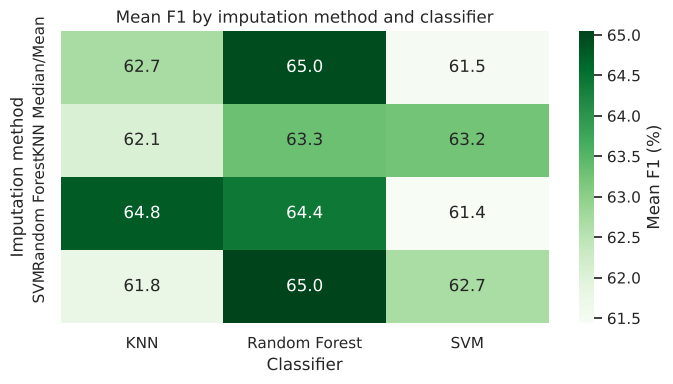

In [6]:
f1 = paper["mean F1"].unstack() * 100
f1 = f1.loc[["Median/Mean", "KNN", "Random Forest", "SVM"], ["KNN", "Random Forest", "SVM"]]
plt.figure(figsize=(7, 4))
sns.heatmap(f1, annot=True, fmt=".1f", cmap="Greens", cbar_kws={"label": "Mean F1 (%)"})
plt.xlabel("Classifier")
plt.ylabel("Imputation method")
plt.title("Mean F1 by imputation method and classifier")
plt.tight_layout()
plt.savefig("images/f1_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

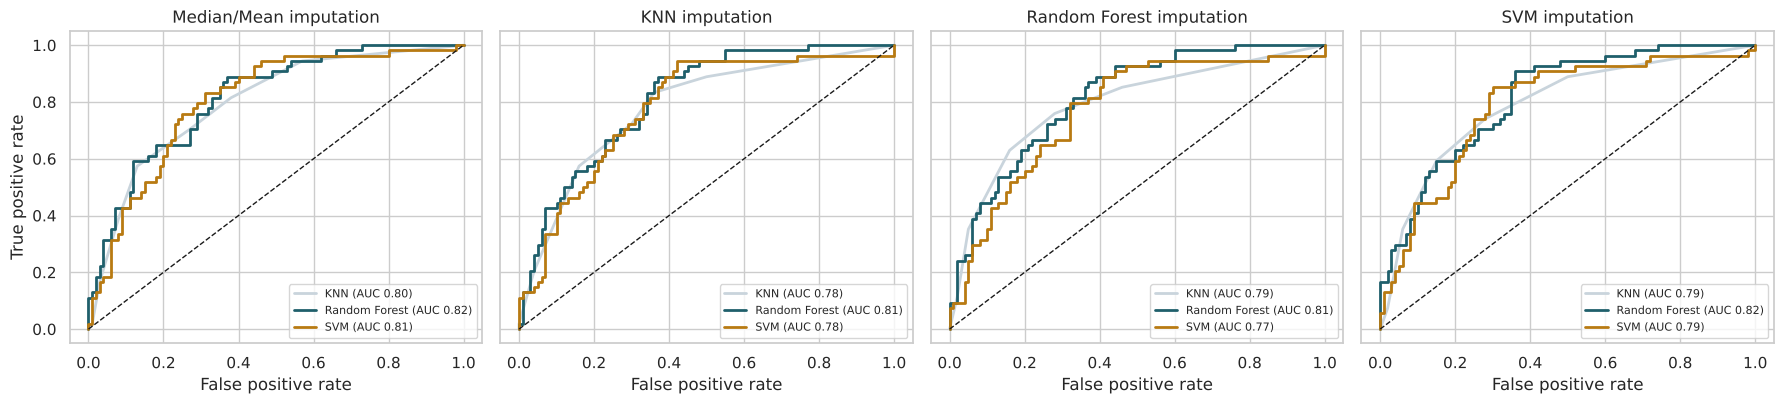

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
colors = {"KNN": GREY, "Random Forest": TEAL, "SVM": AMBER}
for ax, imp_name in zip(axes, ["Median/Mean", "KNN", "Random Forest", "SVM"]):
    for clf_name in ["KNN", "Random Forest", "SVM"]:
        fpr, tpr, _ = roc_data[(imp_name, clf_name)]
        auc = paper.loc[(imp_name, clf_name), "test ROC-AUC"]
        ax.plot(fpr, tpr, color=colors[clf_name], lw=2, label=f"{clf_name} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{imp_name} imputation")
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.show()

**Part A findings.** This re-run uses a different random split and a smaller grid than the paper, and mean F1 lands between 61% and 65% (the paper reported 57–66.5%). Random Forest is the best or within half a point of the best classifier under every imputation method, and has the highest test ROC-AUC in every case. The SVM with a polynomial kernel has the lowest recall: it misses more diabetic patients. The exact ranking shifts between this run and the paper, which is a first sign that the differences are small relative to random variation. Part B tests this directly.

## Part B: revisiting the results (2026)

### B1. Are the differences bigger than noise?

The paper compares single cross-validated averages on one train/test split. With 768 patients, a different random split could easily reorder methods that are only 1–2 points apart.

Here I evaluate each imputation method with **5 × repeated 5-fold stratified cross-validation** on the full dataset (25 fits per method). The imputer is **refitted on the training folds every time**, so no information from the held-out fold leaks into it. I use one fixed, reasonable classifier per type, and report the mean **and the spread** (standard deviation) of F1 and ROC-AUC.

I also add two options the paper didn't test:
- **Median + missing indicators:** median imputation plus a yes/no column for "this value was missing". Sometimes the fact that a test wasn't done is itself informative.
- **No imputation:** `HistGradientBoostingClassifier` handles missing values natively.

In [8]:
def imputers_b():
    base = make_imputers()
    base["Median + missing indicators"] = SimpleImputer(strategy="median", add_indicator=True)
    return base

classifiers_b = {
    "KNN": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=15))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=4, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM (RBF, scaled)": Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", C=1, probability=False))]),
}

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
folds = list(rcv.split(X, y))
scores_b = {}
start = time.time()
for imp_name, imputer in imputers_b().items():
    for train_idx, test_idx in folds:
        # fit each imputer once per fold (on the training fold only), then reuse it for every classifier
        Xtr = imputer.fit_transform(X.iloc[train_idx])
        Xte = imputer.transform(X.iloc[test_idx])
        ytr, yte = y.iloc[train_idx], y.iloc[test_idx]
        for clf_name, clf in classifiers_b.items():
            model = clone(clf).fit(Xtr, ytr)
            score = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(Xte)
            scores_b.setdefault((imp_name, clf_name), []).append((f1_score(yte, model.predict(Xte)), roc_auc_score(yte, score)))

hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE)
for train_idx, test_idx in folds:
    model = clone(hgb).fit(X.iloc[train_idx], y.iloc[train_idx])
    yte = y.iloc[test_idx]
    scores_b.setdefault(("None (native missing-value handling)", "Gradient Boosting"), []).append(
        (f1_score(yte, model.predict(X.iloc[test_idx])), roc_auc_score(yte, model.predict_proba(X.iloc[test_idx])[:, 1])))

rows_b = []
for (imp_name, clf_name), vals in scores_b.items():
    v = np.array(vals)
    rows_b.append({"imputation": imp_name, "classifier": clf_name,
                   "F1 mean": v[:, 0].mean(), "F1 std": v[:, 0].std(),
                   "ROC-AUC mean": v[:, 1].mean(), "ROC-AUC std": v[:, 1].std()})

robust = pd.DataFrame(rows_b).set_index(["imputation", "classifier"])
print(f"Finished in {time.time() - start:.0f}s")
(robust * 100).round(1)

Finished in 353s


F1 mean  F1 std  \
imputation                           classifier                           
Median/Mean                          KNN                   62.2     4.2   
                                     Random Forest         63.6     4.6   
                                     SVM (RBF, scaled)     61.7     4.9   
KNN                                  KNN                   61.9     5.8   
                                     Random Forest         62.4     5.2   
                                     SVM (RBF, scaled)     60.6     5.6   
Random Forest                        KNN                   63.7     6.1   
                                     Random Forest         63.4     4.1   
                                     SVM (RBF, scaled)     60.3     5.9   
SVM                                  KNN                   62.1     4.4   
                                     Random Forest         63.1     4.7   
                                     SVM (RBF, scaled)     61.3     5.1   
Median + missing indicators          KNN                   61.1     5.1   
                                     Random Forest         63.5     4.8   
                                     SVM (RBF, scaled)     59.5     4.9   
None (native missing-value handling) Gradient Boosting     63.7     5.5   

                                                        ROC-AUC mean  \
imputation                           classifier                        
Median/Mean                          KNN                        82.7   
                                     Random Forest              83.8   
                                     SVM (RBF, scaled)          82.9   
KNN                                  KNN                        82.2   
                                     Random Forest              83.7   
                                     SVM (RBF, scaled)          82.6   
Random Forest                        KNN                        82.9   
                                     Random Forest              83.9   
                                     SVM (RBF, scaled)          82.7   
SVM                                  KNN                        82.7   
                                     Random Forest              83.8   
                                     SVM (RBF, scaled)          82.9   
Median + missing indicators          KNN                        81.1   
                                     Random Forest              83.9   
                                     SVM (RBF, scaled)          82.4   
None (native missing-value handling) Gradient Boosting          81.0   

                                                        ROC-AUC std  
imputation                           classifier                      
Median/Mean                          KNN                        3.0  
                                     Random Forest              2.9  
                                     SVM (RBF, scaled)          2.8  
KNN                                  KNN                        3.0  
                                     Random Forest              2.9  
                                     SVM (RBF, scaled)          3.1  
Random Forest                        KNN                        3.2  
                                     Random Forest              2.8  
                                     SVM (RBF, scaled)          3.0  
SVM                                  KNN                        3.1  
                                     Random Forest              3.0  
                                     SVM (RBF, scaled)          2.8  
Median + missing indicators          KNN                        3.3  
                                     Random Forest              2.8  
                                     SVM (RBF, scaled)          3.1  
None (native missing-value handling) Gradient Boosting          3.0

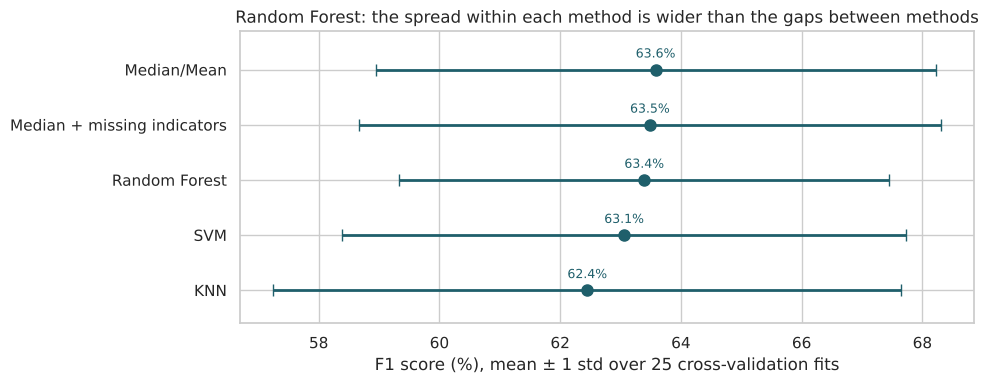

Largest gap between imputation methods: 1.1 points | typical std within a method: 4.7 points


In [9]:
rf_rows = robust.xs("Random Forest", level="classifier").sort_values("F1 mean")
fig, ax = plt.subplots(figsize=(10, 4))
ypos = np.arange(len(rf_rows))
ax.errorbar(rf_rows["F1 mean"] * 100, ypos, xerr=rf_rows["F1 std"] * 100, fmt="o", color=TEAL,
            ecolor=TEAL, elinewidth=2, capsize=4, markersize=8)
for yv, (m, sd) in zip(ypos, zip(rf_rows["F1 mean"] * 100, rf_rows["F1 std"] * 100)):
    ax.text(m, yv + 0.22, f"{m:.1f}%", ha="center", fontsize=9, color=TEAL)
ax.set_yticks(ypos)
ax.set_yticklabels(rf_rows.index)
ax.set_ylim(-0.6, len(rf_rows) - 0.3)
ax.set_xlabel("F1 score (%), mean ± 1 std over 25 cross-validation fits")
ax.set_title("Random Forest: the spread within each method is wider than the gaps between methods")
plt.tight_layout()
plt.savefig("images/imputation_noise.png", dpi=150, bbox_inches="tight")
plt.show()

gap = (rf_rows["F1 mean"].max() - rf_rows["F1 mean"].min()) * 100
print(f"Largest gap between imputation methods: {gap:.1f} points | typical std within a method: {rf_rows['F1 std'].mean() * 100:.1f} points")

For a fixed classifier, the gap between the best and worst imputation method (about 1 point) is much smaller than the variation of any single method across data splits (about ±4.7 points). In other words, **on this dataset, the choice of imputation method does not reliably change classification performance**. Adding missing-value indicators, or skipping imputation entirely with gradient boosting, doesn't stand out either. Random Forest has the highest ROC-AUC under every imputation method, but only by about 1 point.

### B2. How accurately does each method recover the missing values?

Classification scores only show the indirect effect of imputation. To measure imputation quality directly, I take the patients with **complete** records, hide 10% of their values at random, impute them, and compare the imputed values with the true ones.

The error is reported as normalised RMSE (the RMSE divided by the feature's standard deviation), so features on different scales can be compared. A score of 1.0 means no better than guessing the average.

In [10]:
complete = df.dropna(subset=features)[features].reset_index(drop=True)
target_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print(f"Complete records: {len(complete)}")

results = []
for rep in range(5):
    rng = np.random.default_rng(rep)
    masked = complete.copy()
    mask = pd.DataFrame(False, index=complete.index, columns=features)
    for col in target_cols:
        idx = rng.choice(len(complete), size=int(0.10 * len(complete)), replace=False)
        mask.loc[idx, col] = True
    masked = masked.mask(mask)
    for imp_name, imputer in make_imputers().items():
        filled = pd.DataFrame(imputer.fit_transform(masked), columns=features if imp_name != "Median/Mean" else mean_cols + median_cols + other_cols)
        filled = filled[features]
        for col in target_cols:
            m = mask[col].to_numpy()
            rmse = np.sqrt(np.mean((filled.loc[m, col].to_numpy() - complete.loc[m, col].to_numpy()) ** 2))
            results.append({"rep": rep, "imputation": imp_name, "feature": col, "nrmse": rmse / complete[col].std()})

nrmse = pd.DataFrame(results).groupby(["imputation", "feature"])["nrmse"].mean().unstack()
nrmse["Average"] = nrmse.mean(axis=1)
nrmse = nrmse.sort_values("Average")
nrmse.round(3)

Complete records: 385


feature,BMI,BloodPressure,Glucose,Insulin,SkinThickness,Average
imputation,,,,,,
Random Forest,0.746,0.823,0.796,0.861,0.821,0.809
SVM,0.834,0.883,0.841,0.914,0.937,0.882
KNN,0.854,0.931,0.913,0.949,0.886,0.907
Median/Mean,0.888,0.915,0.999,0.971,0.995,0.953


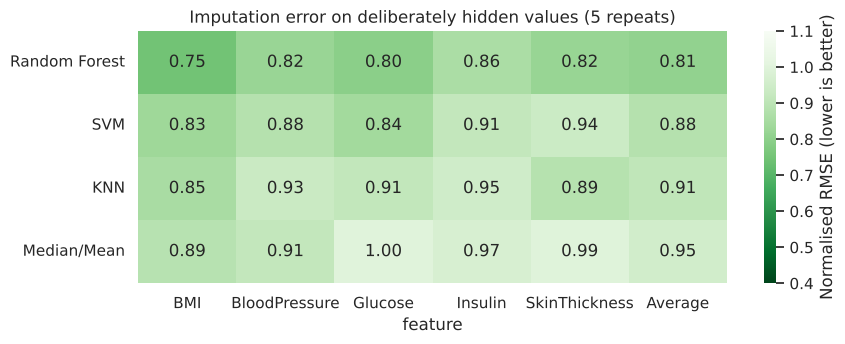

In [11]:
plt.figure(figsize=(9, 3.6))
sns.heatmap(nrmse, annot=True, fmt=".2f", cmap="Greens_r", vmin=0.4, vmax=1.1, cbar_kws={"label": "Normalised RMSE (lower is better)"})
plt.title("Imputation error on deliberately hidden values (5 repeats)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("images/imputation_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

Here the ranking is clearer. **Random Forest imputation recovers hidden values best** (average error 0.81 against 0.95 for the median, about 15% lower), followed by SVM and KNN. The multivariate imputers use relationships between features, for example between BMI and SkinThickness, or Glucose and Insulin. Median imputation always predicts the same value, so its error stays close to 1.0 (no better than guessing the average).

The gains are real but modest: even the best imputer leaves most of the variation unexplained, because the features are only moderately correlated with each other.

Caveat: this test hides values completely at random. In the real data, Insulin and SkinThickness are often missing together, which is harder.

## Conclusions

1. **Random Forest is the most reliable classifier** for this dataset: best or near-best F1, and the highest ROC-AUC under every imputation method, consistent with the paper.
2. **For classification, the imputation method matters little here.** The small F1 differences reported in the paper are smaller than the variation from one data split to another, so they should not be read as one method being better.
3. **For recovering the values themselves, Random Forest imputation is the most accurate**, with about 15% lower error than the median. If imputed values are reported or used directly (for example, to estimate average insulin levels), the method choice matters.
4. **Practical recommendation:** start with simple median imputation inside a pipeline for predictive modelling, and use Random Forest imputation when the imputed values themselves are used.

## Limitations

- One dataset with 768 patients; results may differ on larger datasets or other missing-data patterns.
- Part B2 hides values completely at random, which is easier than the real pattern of missing data.
- Hyperparameters in Part B are fixed rather than tuned, to keep the comparison simple and fair across methods.

## Reference

Pindiyan, A. V., & R.M., P. *Machine Learning-Based Imputation Techniques Analysis and Study.* IEEE. [IEEE Xplore](https://ieeexplore.ieee.org/document/10739330)